In [24]:
import sys
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

parent_dir = os.path.abspath(os.path.join('..'))
if parent_dir not in sys.path:
    sys.path.append(parent_dir)
    
from dustification import DEFAULT_PARAMS, apply_martian_dust_storm

In [11]:
subs = pd.read_csv("submissions.csv")

In [18]:
DEFAULT_PARAMS = {
    "intensity": 0.92,          # Storm density (0.0 = clear, 1.0 = severe storm)

    # Block 2 (Declare the tint of the sand/dust overlay)
    "red_tint": 0.84,
    "green_tint": 0.65,
    "blue_tint": 0.42,

    # Block 3 (Implement dust/fog overlay)
    "gradient_factor": 1.2,     # Shift factor along the column vector
    "baseline_fog": 0.34,       # Baseline fog overlaid on entire image, the whole iamge has 34% fog intensity
    "variable_fog": 0.63,       # Controls the additional fog along gradient; note summation of baseline_fog + variable_fog = intensity of fog at the top of the image
    "maximum_fog": 0.85,        # Caps the maximum fog level that any pixel in the image can reach

    # Block 5 (Adding graininess/sand to image, Gaussian distribution changes the random amount of the filter a pixel receives...)
    # Creates a more realistic Perlin-like filter by adding fine and coarse layers
    "fine_distr": 0.025,        # standard deviation of normal Gaussian distribution for coarse sand
    "coarse_distr": 0.015,      # standard deviation of normal Gaussian distribution for coarse sand
    "noise_scaling": 0.8,       # scales noise amplitude to scale the harshness of the sand filter

    # Block 6 (Implementing Gaussian Blurring)
    "blur_radius": 18.0,        # Sclaes the maximum blur radius for each pixel

    # Block 7
    "final_contrast_factor": 0.25,  # Reduces and smooths final contrast by 25%
}

### Looking at distributions for each

Matplotlib plots were made prettier with AI to help with the code

#### Intensity

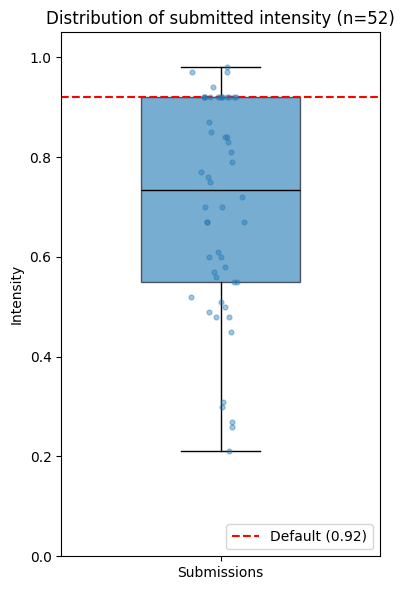

10th percentile: 0.453
90th percentile: 0.92


In [37]:
default_intensity = DEFAULT_PARAMS["intensity"]
intensity = subs["intensity"]

fig, ax = plt.subplots(figsize=(4, 6))

ax.boxplot(intensity, widths=0.5, patch_artist=True,
           boxprops=dict(alpha=0.6),
           medianprops=dict(color="black"))

# Jittered points
x = np.random.normal(1, 0.04, size=len(intensity))
ax.scatter(x, intensity, alpha=0.4, s=12, zorder=3)

ax.axhline(default_intensity, color="red", linestyle="--", linewidth=1.5,
           label=f"Default ({default_intensity})")
ax.set_xticks([1])
ax.set_xticklabels(["Submissions"])
ax.set_ylabel("Intensity")
ax.set_title(f"Distribution of submitted intensity (n={len(intensity)})")
ax.set_ylim(0, 1.05)
ax.legend(loc="lower right")

plt.tight_layout()
plt.show()

q1, q9 = intensity.quantile([0.1, 0.9])
print(f"10th percentile: {q1}")
print(f"90th percentile: {q9}")

#### RGB tint

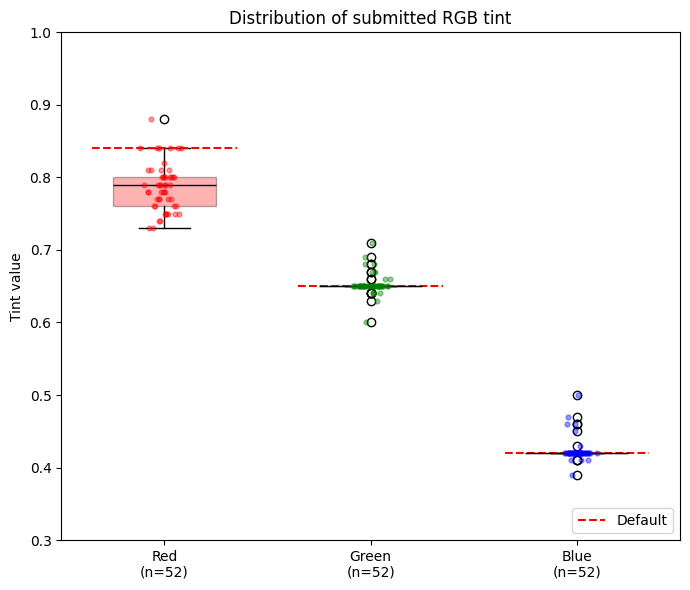

red_tint: 10th = 0.75, 90th = 0.84, default = 0.84
green_tint: 10th = 0.641, 90th = 0.669, default = 0.65
blue_tint: 10th = 0.42, 90th = 0.429, default = 0.42


In [35]:
tints = ["red_tint", "green_tint", "blue_tint"]
colors = ["red", "green", "blue"]
data = [subs[t] for t in tints]

fig, ax = plt.subplots(figsize=(7, 6))

bp = ax.boxplot(data, widths=0.5, patch_artist=True,
                medianprops=dict(color="black"))

for i, (vals, color, t) in enumerate(zip(data, colors, tints), start=1):
    bp["boxes"][i - 1].set_facecolor(color)
    bp["boxes"][i - 1].set_alpha(0.3)

    # Jittered points
    x = np.random.normal(i, 0.04, size=len(vals))
    ax.scatter(x, vals, alpha=0.4, s=12, color=color, zorder=3)
    ax.hlines(DEFAULT_PARAMS[t], i - 0.35, i + 0.35, color="red",
              linestyle="--", linewidth=1.5,
              label="Default" if i == 1 else None)

ax.set_xticks(range(1, len(tints) + 1))
ax.set_xticklabels([f"{t.split('_')[0].title()}\n(n={len(d)})" for t, d in zip(tints, data)])
ax.set_ylabel("Tint value")
ax.set_title("Distribution of submitted RGB tint")
ax.set_ylim(0.3, 1.0)
ax.legend(loc="lower right")

plt.tight_layout()
plt.show()

for t, vals in zip(tints, data):
    q25, q75 = vals.quantile([0.1, 0.9])
    print(f"{t}: 10th = {q25}, 90th = {q75}, default = {DEFAULT_PARAMS[t]}")

#### Dust/fog overlay

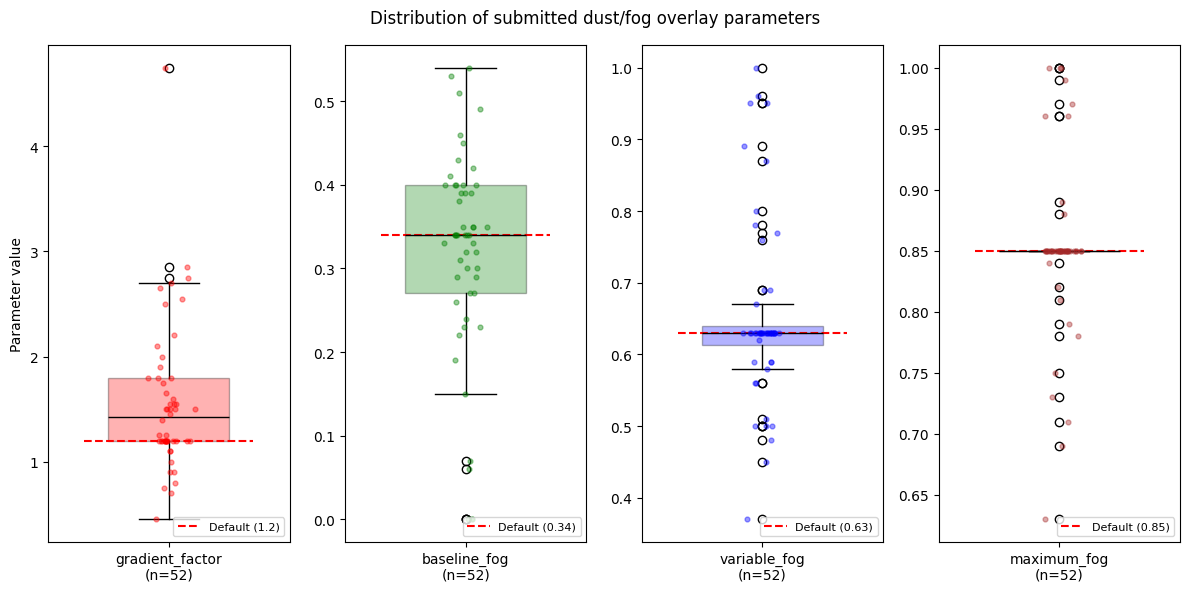

gradient_factor: 10th = 0.91, 90th = 2.545, default = 1.2
baseline_fog: 10th = 0.15400000000000003, 90th = 0.44799999999999995, default = 0.34
variable_fog: 10th = 0.501, 90th = 0.8629999999999999, default = 0.63
maximum_fog: 10th = 0.781, 90th = 0.96, default = 0.85


In [38]:
fog_params = ["gradient_factor", "baseline_fog", "variable_fog", "maximum_fog"]
colors = ["red", "green", "blue", "brown"]

fig, axes = plt.subplots(1, len(fog_params), figsize=(12, 6))

for ax, p, color in zip(axes, fog_params, colors):
    vals = subs[p].dropna()

    bp = ax.boxplot(vals, widths=0.5, patch_artist=True,
                    medianprops=dict(color="black"))
    bp["boxes"][0].set_facecolor(color)
    bp["boxes"][0].set_alpha(0.3)

    # Jittered points
    x = np.random.normal(1, 0.04, size=len(vals))
    ax.scatter(x, vals, alpha=0.4, s=12, color=color, zorder=3)

    ax.hlines(DEFAULT_PARAMS[p], 0.65, 1.35, color="red",
              linestyle="--", linewidth=1.5,
              label=f"Default ({DEFAULT_PARAMS[p]})")

    ax.set_xticks([1])
    ax.set_xticklabels([f"{p}\n(n={len(vals)})"])
    ax.legend(loc="lower right", fontsize=8)

axes[0].set_ylabel("Parameter value")
fig.suptitle("Distribution of submitted dust/fog overlay parameters")

plt.tight_layout()
plt.show()

for p in fog_params:
    vals = subs[p].dropna()
    q10, q90 = vals.quantile([0.1, 0.9])
    print(f"{p}: 10th = {q10}, 90th = {q90}, default = {DEFAULT_PARAMS[p]}")

#### Grainness

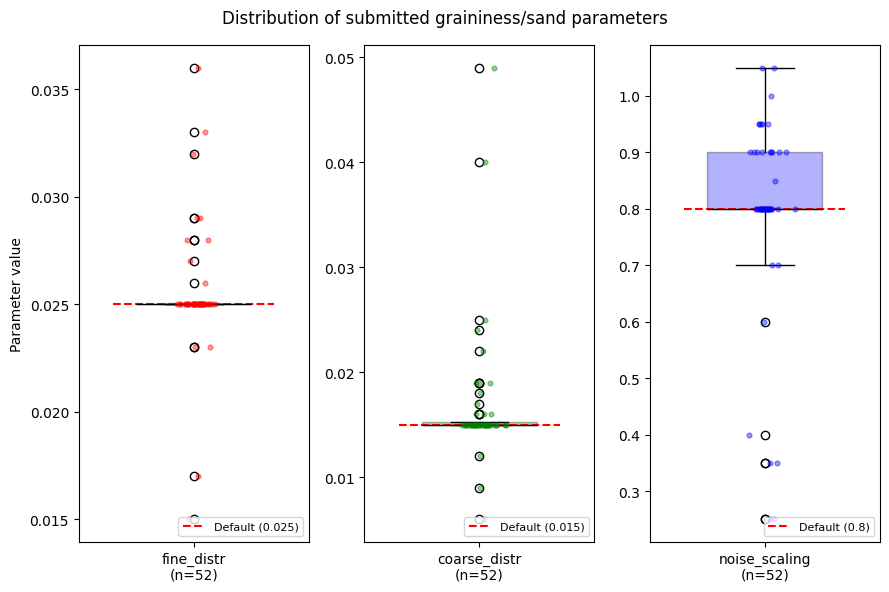

fine_distr: 10th = 0.025, 90th = 0.028, default = 0.025
coarse_distr: 10th = 0.015, 90th = 0.019, default = 0.015
noise_scaling: 10th = 0.61, 90th = 0.95, default = 0.8


In [40]:
grain_params = ["fine_distr", "coarse_distr", "noise_scaling"]
colors = ["red", "green", "blue"]

fig, axes = plt.subplots(1, len(grain_params), figsize=(9, 6))

for ax, p, color in zip(axes, grain_params, colors):
    vals = subs[p].dropna()

    bp = ax.boxplot(vals, widths=0.5, patch_artist=True,
                    medianprops=dict(color="black"))
    bp["boxes"][0].set_facecolor(color)
    bp["boxes"][0].set_alpha(0.3)

    # Jittered points
    x = np.random.normal(1, 0.04, size=len(vals))
    ax.scatter(x, vals, alpha=0.4, s=12, color=color, zorder=3)

    ax.hlines(DEFAULT_PARAMS[p], 0.65, 1.35, color="red",
              linestyle="--", linewidth=1.5,
              label=f"Default ({DEFAULT_PARAMS[p]})")

    ax.set_xticks([1])
    ax.set_xticklabels([f"{p}\n(n={len(vals)})"])
    ax.legend(loc="lower right", fontsize=8)

axes[0].set_ylabel("Parameter value")
fig.suptitle("Distribution of submitted graininess/sand parameters")

plt.tight_layout()
plt.show()

for p in grain_params:
    vals = subs[p].dropna()
    q10, q90 = vals.quantile([0.1, 0.9])
    print(f"{p}: 10th = {q10}, 90th = {q90}, default = {DEFAULT_PARAMS[p]}")

#### Gaussian Blurring

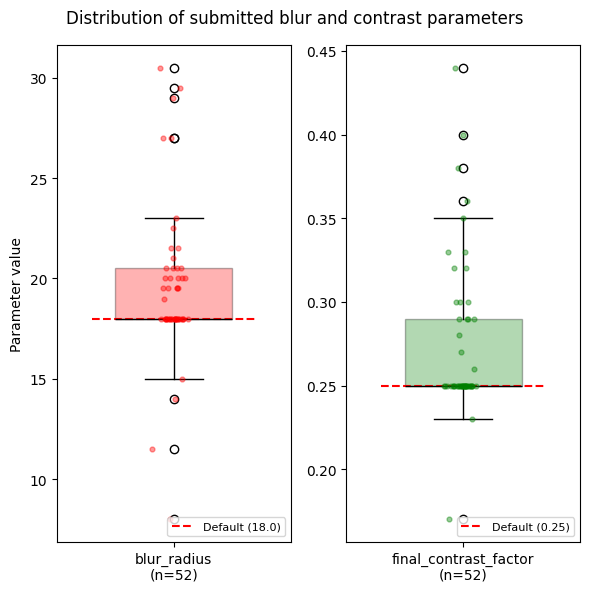

blur_radius: 10th = 18.0, 90th = 22.95, default = 18.0
final_contrast_factor: 10th = 0.25, 90th = 0.33, default = 0.25


In [41]:
other_params = ["blur_radius", "final_contrast_factor"]
colors = ["red", "green"]

fig, axes = plt.subplots(1, len(other_params), figsize=(6, 6))

for ax, p, color in zip(axes, other_params, colors):
    vals = subs[p].dropna()

    bp = ax.boxplot(vals, widths=0.5, patch_artist=True,
                    medianprops=dict(color="black"))
    bp["boxes"][0].set_facecolor(color)
    bp["boxes"][0].set_alpha(0.3)

    # Jittered points
    x = np.random.normal(1, 0.04, size=len(vals))
    ax.scatter(x, vals, alpha=0.4, s=12, color=color, zorder=3)

    ax.hlines(DEFAULT_PARAMS[p], 0.65, 1.35, color="red",
              linestyle="--", linewidth=1.5,
              label=f"Default ({DEFAULT_PARAMS[p]})")

    ax.set_xticks([1])
    ax.set_xticklabels([f"{p}\n(n={len(vals)})"])
    ax.legend(loc="lower right", fontsize=8)

axes[0].set_ylabel("Parameter value")
fig.suptitle("Distribution of submitted blur and contrast parameters")

plt.tight_layout()
plt.show()

for p in other_params:
    vals = subs[p].dropna()
    q10, q90 = vals.quantile([0.1, 0.9])
    print(f"{p}: 10th = {q10}, 90th = {q90}, default = {DEFAULT_PARAMS[p]}")

#### Final List for Nora

intensity = [0.453, 0.92]
red_tint = [0.75, 0.84]
green_tint = [0.641, 0.669]
blue_tint = [0.42, 0.429]
gradient_factor = [0.91, 2.55]
baseline_fog = [0.154, 0.448]
variable_fog = [0.501, 0.863]
maximum_fog = [0.781, 0.96]
fine_distr = [0.025, 0.028]
coarse_distr = [0.015, 0.019]
noise_scaling = [0.61, 0.95]
blur_radius = [18.0, 22.95]
final_contrast_factor = [0.25, 0.33]

## Did settings vary alot by person?

In [48]:
subs["username"] = subs["username"].str.strip().str.lower()
params = list(DEFAULT_PARAMS.keys())
summary = (subs.groupby("username")[params]
               .quantile([0.1, 0.5, 0.9])
               .unstack())
counts = subs.groupby("username").size().rename("n")
display(summary)

intensity              red_tint              green_tint              \
               0.1   0.5    0.9      0.1   0.5    0.9        0.1   0.5   0.9   
username                                                                       
isaac        0.330  0.67  0.920    0.742  0.78  0.830      0.650  0.65  0.65   
noah         0.446  0.70  0.846    0.758  0.80  0.840      0.648  0.65  0.68   
nora         0.535  0.92  0.955    0.750  0.79  0.825      0.640  0.65  0.66   
warren       0.586  0.67  0.691    0.750  0.76  0.791      0.650  0.65  0.65   

         blue_tint  ... coarse_distr noise_scaling              blur_radius  \
               0.1  ...          0.9           0.1    0.5   0.9         0.1   
username            ...                                                       
isaac        0.412  ...       0.0168         0.620  0.800  0.80        14.8   
noah         0.420  ...       0.0190         0.800  0.900  0.96        18.0   
nora         0.415  ...       0.0155         0.525  0.800  0.80        18.0   
warren       0.420  ...       0.0463         0.365  0.675  1.02        14.2   

                       final_contrast_factor                
            0.5    0.9                   0.1    0.5    0.9  
username                                                    
isaac     18.00  19.20                  0.25  0.250  0.250  
noah      20.00  21.50                  0.25  0.300  0.368  
nora      18.00  22.75                  0.25  0.250  0.250  
warren    23.75  28.75                  0.25  0.275  0.356  

[4 rows x 39 columns]

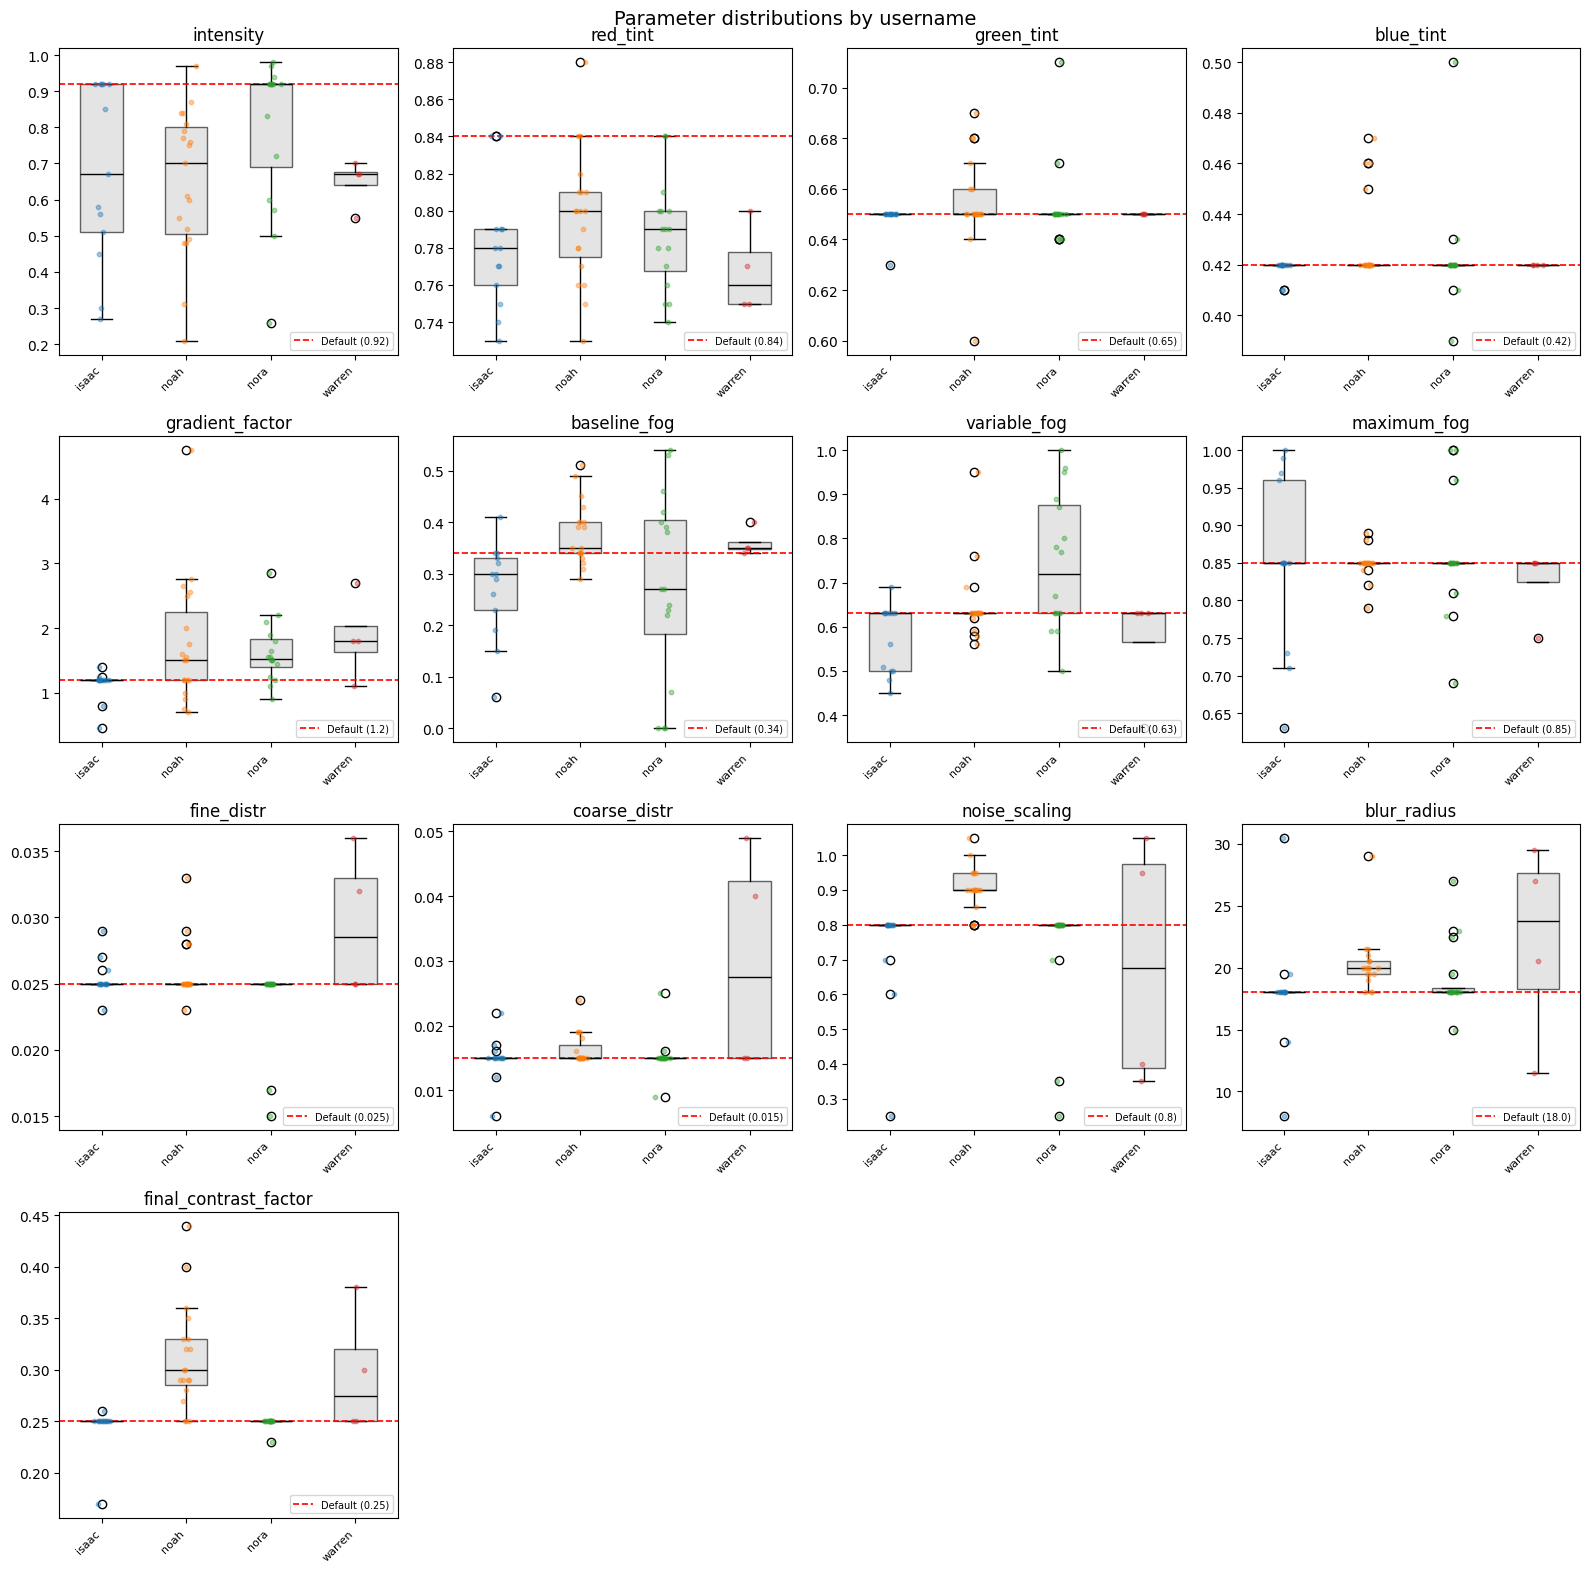

In [49]:
users = sorted(subs["username"].dropna().unique())
ncols = 4
nrows = int(np.ceil(len(params) / ncols))

fig, axes = plt.subplots(nrows, ncols, figsize=(4 * ncols, 4 * nrows))
axes = axes.flatten()

for ax, p in zip(axes, params):
    data = [subs.loc[subs["username"] == u, p].dropna() for u in users]

    ax.boxplot(data, widths=0.5, patch_artist=True,
               boxprops=dict(facecolor="lightgray", alpha=0.6),
               medianprops=dict(color="black"))

    # Jittered points per user
    for i, vals in enumerate(data, start=1):
        x = np.random.normal(i, 0.04, size=len(vals))
        ax.scatter(x, vals, alpha=0.4, s=10, zorder=3)

    ax.axhline(DEFAULT_PARAMS[p], color="red", linestyle="--", linewidth=1.2,
               label=f"Default ({DEFAULT_PARAMS[p]})")

    ax.set_title(p)
    ax.set_xticks(range(1, len(users) + 1))
    ax.set_xticklabels(users, rotation=45, ha="right", fontsize=8)
    ax.legend(fontsize=7, loc="lower right")

# Hide any unused panels
for ax in axes[len(params):]:
    ax.set_visible(False)

fig.suptitle("Parameter distributions by username", fontsize=14)
plt.tight_layout()
plt.show()